# Kutubxonalarni chaqirish


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

# Datasetni yuklash va birlamchi tahlillar

In [2]:
df = pd.read_csv("dataset.csv")
df.head()

,product_id,category,region,store_type,year,month,avg_unit_price,units_sold,returns,discount_pct,promo_active,customer_rating,competitor_price_index,marketing_spend,monthly_revenue
0,P1001,smartphones,Tashkent,offline,2023,1,581.95,298,21,28.5,True,4.6,0.86,5743.41,124478.76
1,P1002,smartphones,Tashkent,offline,2023,2,562.49,291,16,19.4,True,4.5,1.13,3337.52,124675.91
2,P1003,smartphones,Tashkent,both,2023,3,502.26,361,14,4.8,False,4.4,1.15,10194.22,165918.58
3,P1004,smartphones,Tashkent,both,2023,4,577.21,408,21,1.9,False,4.4,1.14,13449.78,219136.04
4,P1005,smartphones,Tashkent,both,2023,5,469.80,449,16,1.1,False,4.5,0.89,7736.95,217280.60


In [3]:
df.shape

(2400, 15)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2400 entries, 0 to 2399
Data columns (total 15 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   product_id              2400 non-null   object 
 1   category                2400 non-null   object 
 2   region                  2400 non-null   object 
 3   store_type              2400 non-null   object 
 4   year                    2400 non-null   int64  
 5   month                   2400 non-null   int64  
 6   avg_unit_price          2400 non-null   float64
 7   units_sold              2400 non-null   int64  
 8   returns                 2400 non-null   int64  
 9   discount_pct            2400 non-null   float64
 10  promo_active            2304 non-null   object 
 11  customer_rating         2328 non-null   float64
 12  competitor_price_index  2352 non-null   float64
 13  marketing_spend         2400 non-null   float64
 14  monthly_revenue         2400 non-null   

In [5]:
df.describe()

,year,month,avg_unit_price,units_sold,returns,discount_pct,customer_rating,competitor_price_index,marketing_spend,monthly_revenue
count,2400.000000,2400.000000,2400.000000,2400.000000,2400.000000,2400.000000,2328.000000,2352.000000,2400.000000,2.400000e+03
mean,2023.500000,6.500000,268.426929,237.990417,11.429583,9.076833,4.114046,1.027151,2228.115308,3.910945e+04
std,0.500104,3.452772,230.588458,249.114313,13.679169,10.840218,0.350572,0.100370,2935.732043,5.192661e+04
min,2023.000000,1.000000,11.350000,27.000000,-5.000000,0.000000,3.000000,0.850000,49.550000,1.626530e+03
25%,2023.000000,3.750000,88.610000,76.750000,3.000000,1.700000,3.900000,0.940000,637.975000,1.234183e+04
50%,2023.500000,6.500000,177.625000,174.000000,7.000000,3.500000,4.100000,1.030000,1304.965000,2.504608e+04
75%,2024.000000,9.250000,422.410000,294.000000,15.000000,17.700000,4.400000,1.110000,2462.125000,4.070096e+04
max,2024.000000,12.000000,884.170000,1896.000000,113.000000,35.000000,5.000000,1.200000,24229.630000,1.278254e+06


Demak birlamchi tahlillardan quyidagilarni aniqlab olindi:
- dataset 15 ustun va 2400 qatordan iborat ustunlar quyidagicha
  1. product_id               — Mahsulotning idsi
  2. category                 — Mahsulot kategoriyasi
  3. region                   — Hudud
  4. store_type               — Savdo turi (offline, online yoki ikkalasi)
  5. year                     — Yil
  6. month                    — Oy
  7. avg_unit_price           — Mahsulotning o'rtacha birlik narxi
  8. units_sold               — Sotilgan mahsulotlar soni
  9. returns                  — Qaytarilgan mahsulotlar soni
  10. discount_pct             — Chegirma foizi
  11. promo_active             — Aksiya mavjudligi
  12. customer_rating          — Mijozlar bahosi
  13. competitor_price_index   — Raqobatchilar narx indeksi
  14. marketing_spend         — Marketing uchun sarflangan mablag'
  15. monthly_revenue          — Oylik tushum
- promo_active, customer_rating va competitor_price_index ustunlarida yetishmayotgan qiymatlar mavjud.
- Qolgan ustunlarda yetishmayotgan qiymatlar mavjud emas.
- Ma'lumotlar 2023–2024 yillarni qamrab oladi.

# Chuqur tahlil

## 1. product_id ustuni tahlil uchun zarur emas shuning uchun uni tashlab yubordim

In [6]:
df.drop("product_id", axis=1, inplace=True)
df.head()

,category,region,store_type,year,month,avg_unit_price,units_sold,returns,discount_pct,promo_active,customer_rating,competitor_price_index,marketing_spend,monthly_revenue
0,smartphones,Tashkent,offline,2023,1,581.95,298,21,28.5,True,4.6,0.86,5743.41,124478.76
1,smartphones,Tashkent,offline,2023,2,562.49,291,16,19.4,True,4.5,1.13,3337.52,124675.91
2,smartphones,Tashkent,both,2023,3,502.26,361,14,4.8,False,4.4,1.15,10194.22,165918.58
3,smartphones,Tashkent,both,2023,4,577.21,408,21,1.9,False,4.4,1.14,13449.78,219136.04
4,smartphones,Tashkent,both,2023,5,469.80,449,16,1.1,False,4.5,0.89,7736.95,217280.60


## 2. NaN qiymatlarni tahlil qilish




In [7]:
# promo_active qiymati mavjud bo'lmagan qatorlarni ko'rish

df[df['promo_active'].isna()]

,category,region,store_type,year,month,avg_unit_price,units_sold,returns,discount_pct,promo_active,customer_rating,competitor_price_index,marketing_spend,monthly_revenue
5,smartphones,Tashkent,offline,2023,6,535.04,250,19,1.3,NaN,4.4,1.08,7563.84,121987.51
14,smartphones,Tashkent,both,2024,3,553.60,300,19,0.3,NaN,4.3,1.02,8800.28,155094.92
20,smartphones,Tashkent,online,2024,9,515.78,360,27,20.0,NaN,3.7,1.04,4277.21,137403.79
21,smartphones,Tashkent,both,2024,10,543.18,512,15,4.2,NaN,4.5,1.02,9128.86,258622.12
31,smartphones,Tashkent,both,2023,8,481.65,382,27,0.4,NaN,4.3,1.17,9702.81,170301.81
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2196,cameras,Tashkent,both,2024,1,384.07,56,1,27.6,NaN,4.3,1.03,1126.27,15293.67
2217,cameras,Samarkand,offline,2023,10,367.27,63,3,34.6,NaN,4.7,1.18,666.55,14411.67
2261,cameras,Bukhara,offline,2023,6,419.38,29,0,4.0,NaN,4.3,1.03,263.07,11675.54
2277,cameras,Bukhara,online,2024,10,446.03,38,2,3.9,NaN,3.7,1.02,814.34,15430.85


- bunda aniq bir bog'liqlikni topish qiyin. Shuni tushunsa bo'ladi discount_pct ya'ni chegirma foizi  kam va ko'pini orasida farq katta bo'lgan shundan foydalandim. Yani chegirma foizi 15 foizdan kam bo'lsa promo yo'q 15 foizdan ko'p bo'lsa promo mavjud

In [8]:
df['promo_active'] = df['promo_active'].fillna(
    df['discount_pct'] > 15
)
df['promo_active'].value_counts()

C:\Users\shoki\AppData\Local\Temp\ipykernel_24900\1626233964.py:1: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['promo_active'] = df['promo_active'].fillna(


promo_active
False    1704
True      696
Name: count, dtype: int64

In [9]:
# costumer_rating qiymati mavjud bo'lmagan qatorlarni ko'rish

df[df['customer_rating'].isna()]

,category,region,store_type,year,month,avg_unit_price,units_sold,returns,discount_pct,promo_active,customer_rating,competitor_price_index,marketing_spend,monthly_revenue
17,smartphones,Tashkent,online,2024,6,616.61,241,5,4.3,False,NaN,0.93,8936.79,150403.61
66,smartphones,Samarkand,online,2024,7,587.25,289,9,18.7,True,NaN,1.19,8736.64,133681.59
153,smartphones,Andijan,offline,2023,10,608.47,218,13,2.3,False,NaN,1.07,9111.47,121867.41
240,wireless_audio,Tashkent,online,2023,1,96.73,240,8,0.4,False,NaN,1.06,736.69,22351.59
245,wireless_audio,Tashkent,online,2023,6,97.55,337,16,2.0,False,NaN,1.07,1134.86,30687.28
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2267,cameras,Bukhara,online,2023,12,435.39,41,2,0.0,False,NaN,0.87,555.95,18338.63
2269,cameras,Bukhara,online,2024,2,410.27,40,2,0.9,False,NaN,1.09,922.65,15449.95
2275,cameras,Bukhara,online,2024,8,372.33,64,4,22.8,True,NaN,1.00,1100.55,17246.33
2316,cameras,Andijan,both,2024,1,393.11,58,2,0.7,False,NaN,0.96,1308.09,21860.06


- bunga aniq bir ustunni bog'lash juda ham qiyin. Bundagi NaN qiymatlarni median bilan to'ldirish eng yaxshi qaror

In [10]:
median_rating = df['customer_rating'].median()

df['customer_rating'] = df['customer_rating'].fillna(median_rating)

print("Median qiymat:", median_rating)

Median qiymat: 4.1


In [11]:
# competitor_price_index qiymati mavjud bo'lmagan qatorlarni ko'rish

df[df['competitor_price_index'].isna()]

,category,region,store_type,year,month,avg_unit_price,units_sold,returns,discount_pct,promo_active,customer_rating,competitor_price_index,marketing_spend,monthly_revenue
8,smartphones,Tashkent,offline,2023,9,537.65,265,14,1.2,False,4.3,NaN,6263.87,133330.75
196,smartphones,Namangan,both,2023,5,545.46,524,41,20.7,True,4.0,NaN,20311.47,208921.54
210,smartphones,Namangan,offline,2024,7,555.57,230,17,1.4,False,4.3,NaN,5769.88,116679.70
266,wireless_audio,Tashkent,online,2023,3,95.19,341,26,0.5,False,4.5,NaN,2337.85,29834.93
272,wireless_audio,Tashkent,both,2023,9,102.92,294,18,1.0,False,4.7,NaN,2298.54,30371.61
307,wireless_audio,Samarkand,online,2024,8,97.49,368,21,25.5,True,4.1,NaN,2428.50,25202.63
311,wireless_audio,Samarkand,offline,2024,12,80.66,452,30,3.0,False,4.4,NaN,2728.50,33017.36
337,wireless_audio,Bukhara,online,2023,2,86.99,288,8,4.3,False,4.4,NaN,1167.14,23309.84
487,gaming,Tashkent,both,2023,8,193.13,220,8,0.4,False,3.9,NaN,3298.61,40779.79
500,gaming,Tashkent,offline,2024,9,206.88,252,7,30.5,True,4.5,NaN,3082.93,35226.49


- bunda ham aniq bir ustunni bog'lash qiyin. Bundagi NaN qiymatlarni ham median bilan to'ldirdim

In [12]:
median_competitor = df['competitor_price_index'].median()

df['competitor_price_index'] = df['competitor_price_index'].fillna(
    median_competitor
)

print("Median qiymat:", median_competitor)

Median qiymat: 1.03


## 3. obyekt tipli ustunlarni tahlil qilish va kodlashga tayyorlash

In [13]:
df['category'].value_counts()

category
smartphones        240
wireless_audio     240
gaming             240
smart_home         240
cables_chargers    240
storage_devices    240
laptops            240
tablets            240
wearables          240
cameras            240
Name: count, dtype: int64

- category - 10 ta kategoriya, har biri 240 tadan - balanslangan.

In [14]:
df['region'].value_counts()

region
Tashkent     480
Samarkand    480
Bukhara      480
Andijan      480
Namangan     480
Name: count, dtype: int64

- region - 5 ta hudud, har biri 480 tadan - balanslangan.

In [15]:
df['store_type'].value_counts()

store_type
offline    863
online     839
both       698
Name: count, dtype: int64

- store_type - offline 863, online 839, both 698 - biroz farq bor, lekin keskin nomutanosiblik emas.

In [16]:
df['promo_active'].value_counts()

promo_active
False    1704
True      696
Name: count, dtype: int64

- promo_active - False 1704, True 696 - farq katta lekin jiddiy zarar bermaydi

In [17]:
df['promo_active'] = df['promo_active'].astype(int)

df['promo_active'].value_counts()

promo_active
0    1704
1     696
Name: count, dtype: int64

In [18]:
# regression modelda kerak bo'ladi
df_new=df.copy()
df_new.head()

,category,region,store_type,year,month,avg_unit_price,units_sold,returns,discount_pct,promo_active,customer_rating,competitor_price_index,marketing_spend,monthly_revenue
0,smartphones,Tashkent,offline,2023,1,581.95,298,21,28.5,1,4.6,0.86,5743.41,124478.76
1,smartphones,Tashkent,offline,2023,2,562.49,291,16,19.4,1,4.5,1.13,3337.52,124675.91
2,smartphones,Tashkent,both,2023,3,502.26,361,14,4.8,0,4.4,1.15,10194.22,165918.58
3,smartphones,Tashkent,both,2023,4,577.21,408,21,1.9,0,4.4,1.14,13449.78,219136.04
4,smartphones,Tashkent,both,2023,5,469.80,449,16,1.1,0,4.5,0.89,7736.95,217280.60


## 4. Hisoblash va grafiglar

In [19]:
df['hisoblangan_daromad'] = (
    df['avg_unit_price'] * (df['units_sold']-df['returns'])*(1-df['discount_pct']/100)
)

df[['avg_unit_price',
    'units_sold',
    'discount_pct',
    'returns',
    'monthly_revenue',
    'hisoblangan_daromad']].head(10)

,avg_unit_price,units_sold,discount_pct,returns,monthly_revenue,hisoblangan_daromad
0,581.95,298,28.5,21,124478.76,115258.10725
1,562.49,291,19.4,16,124675.91,124675.90850
2,502.26,361,4.8,14,165918.58,165918.57744
3,577.21,408,1.9,21,219136.04,219136.04487
4,469.80,449,1.1,16,217280.60,201185.74260
5,535.04,250,1.3,19,121987.51,121987.51488
6,559.64,229,4.9,13,114959.01,114959.01024
7,516.75,326,33.9,23,103496.24,103496.24025
8,537.65,265,1.2,14,133330.75,133330.74820
9,512.34,289,0.2,7,144190.92,144190.92024


- monthly_revenue mustaqil ravishda berilgan iqtisodiy ko‘rsatkich emas, balki avg_unit_price, units_sold, returns va discount_pct asosida hisoblangan. Formula amalda deyarli barcha kuzatuvlarda monthly_revenue bilan mos keladi.

### Sotilgan mahsulotlar soni va narxi orasidagi bog'liqlik

- Maqsad: qaysi bir kategorya ko'p sotilib kam foyda keltiryabdi aniqlash

In [20]:
category_analysis = (
    df.groupby('category').agg(
          avg_revenue=('monthly_revenue', 'mean'),
          avg_units_sold=('units_sold', 'mean'),
          avg_discount=('discount_pct', 'mean'),
          avg_marketing=('marketing_spend', 'mean')
      ).sort_values('avg_revenue', ascending=False)
)

category_analysis

,avg_revenue,avg_units_sold,avg_discount,avg_marketing
category,,,,
smartphones,165734.517667,354.641667,10.583750,9424.151875
laptops,53011.948792,79.770833,8.814583,3001.498667
gaming,42036.123792,231.445833,9.109583,2482.971208
tablets,30617.461625,114.762500,8.830417,1767.578792
wireless_audio,29813.865000,377.475000,9.185833,1677.025625
wearables,24279.027667,180.870833,9.027917,1369.858208
cameras,18166.166917,49.145833,8.747083,1001.302000
smart_home,11327.894625,115.695833,8.863750,637.186750
cables_chargers,9075.537833,699.979167,9.105000,515.864583


- bunda kategoriyalar bo'yicha o'rtacha hisob kitoblar

In [21]:
# Kategoriyalar bo'yicha o'rtacha oylik tushum
category_revenue = (
    df.groupby('category')['monthly_revenue'].mean().sort_values(ascending=False)
)

category_revenue

category
smartphones        165734.517667
laptops             53011.948792
gaming              42036.123792
tablets             30617.461625
wireless_audio      29813.865000
wearables           24279.027667
cameras             18166.166917
smart_home          11327.894625
cables_chargers      9075.537833
storage_devices      7031.973750
Name: monthly_revenue, dtype: float64

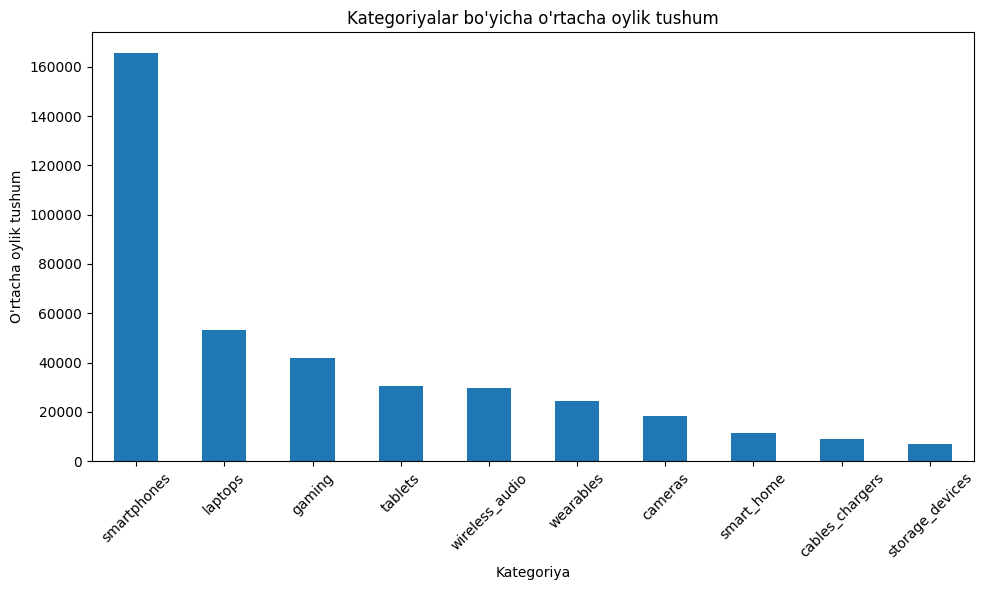

In [22]:
plt.figure(figsize=(10, 6))

category_revenue.plot(kind='bar')

plt.title("Kategoriyalar bo'yicha o'rtacha oylik tushum")
plt.xlabel("Kategoriya")
plt.ylabel("O'rtacha oylik tushum")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

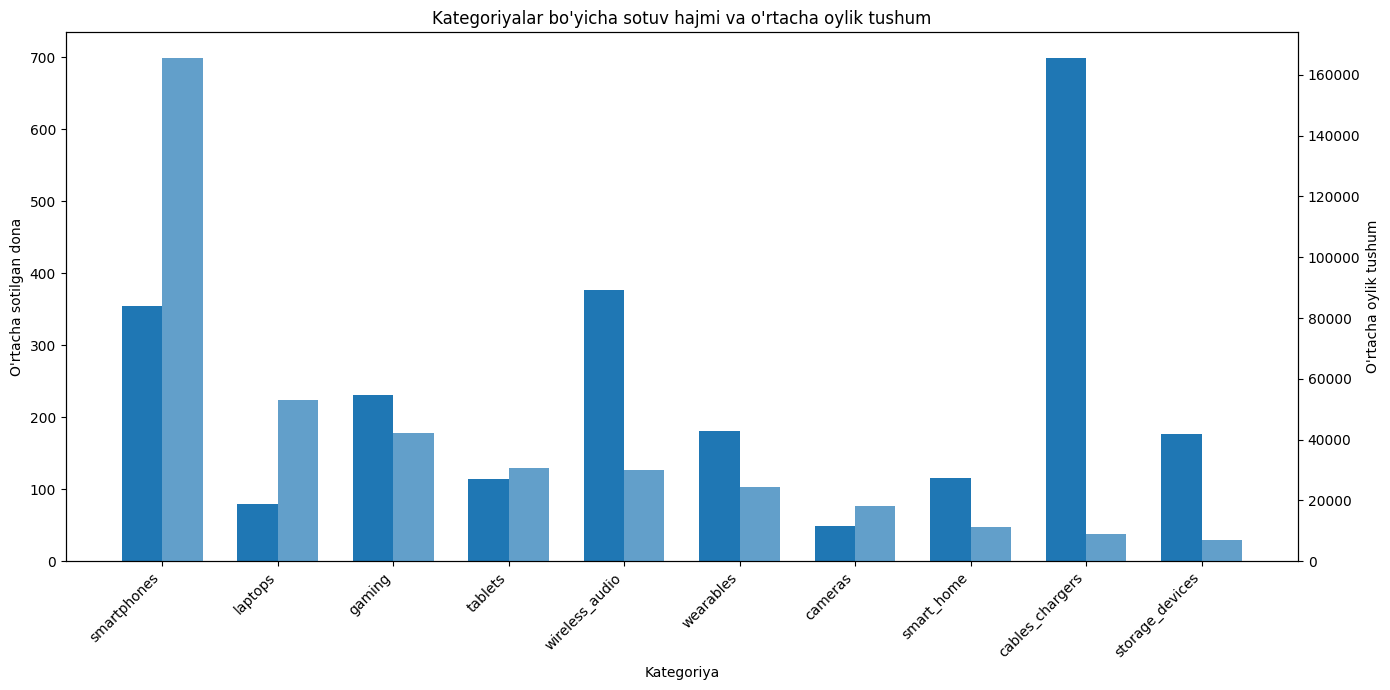

In [23]:
# Sotuv soni va oylik tushumni taqqoslash

categories = category_analysis.index

x = np.arange(len(categories))
width = 0.35

fig, ax1 = plt.subplots(figsize=(14, 7))

# Sotuv soni
ax1.bar(
    x - width/2,
    category_analysis['avg_units_sold'],
    width,
    label="O'rtacha sotuv (dona)"
)

ax1.set_xlabel("Kategoriya")
ax1.set_ylabel("O'rtacha sotilgan dona")
ax1.set_xticks(x)
ax1.set_xticklabels(categories, rotation=45, ha='right')

# Tushum uchun ikkinchi Y o'qi
ax2 = ax1.twinx()

ax2.bar(
    x + width/2,
    category_analysis['avg_revenue'],
    width,
    label="O'rtacha oylik tushum",
    alpha=0.7
)

ax2.set_ylabel("O'rtacha oylik tushum")

plt.title("Kategoriyalar bo'yicha sotuv hajmi va o'rtacha oylik tushum")

fig.tight_layout()
plt.show()

- Smartphones kategoriyasida ham sotuv hajmi, ham o‘rtacha oylik tushum yuqori. Cables & chargers kategoriyasida esa mahsulotlar juda ko‘p sotilayotgan bo‘lsa-da, o‘rtacha oylik tushum nisbatan past. Bu yuqori sotuv soni har doim ham yuqori moliyaviy natijani anglatmasligini ko‘rsatadi.

### Hudud va kategoriya bo'yicha o'rtacha tushum


- Maqsad: Qaysi hududda qaysi kategoryadan yaxshi yoki yomon tushum tushayotganini aniqlash

In [24]:
region_category = pd.pivot_table(
    df,
    values='monthly_revenue',
    index='category',
    columns='region',
    aggfunc='mean'
)

region_category

region,Andijan,Bukhara,Namangan,Samarkand,Tashkent
category,,,,,
cables_chargers,8993.683542,8892.447500,8065.595000,11054.332500,8371.630625
cameras,18666.112500,18003.047917,18080.828542,18839.198958,17241.646667
gaming,41838.534375,42711.568333,40785.839583,42607.966042,42236.710625
laptops,54687.496250,53456.843542,54128.786042,50776.527500,52010.090625
smart_home,8682.833333,8248.464583,8364.956875,8085.431042,23257.787292
smartphones,158108.614375,193585.152708,160603.241042,161412.392500,154963.187708
storage_devices,6907.676250,6745.805000,7473.027500,7589.761667,6443.598333
tablets,30546.235208,29985.230417,29999.568333,30191.406667,32364.867500
wearables,24394.575417,24932.732500,24174.520625,24055.031667,23838.278125


In [25]:
category_avg_revenue = region_category.mean(axis=1)

category_avg_revenue

category
cables_chargers      9075.537833
cameras             18166.166917
gaming              42036.123792
laptops             53011.948792
smart_home          11327.894625
smartphones        165734.517667
storage_devices      7031.973750
tablets             30617.461625
wearables           24279.027667
wireless_audio      29813.865000
dtype: float64

In [26]:
region_category_ratio = region_category.div(
    category_avg_revenue,
    axis=0
)

region_category_ratio

region,Andijan,Bukhara,Namangan,Samarkand,Tashkent
category,,,,,
cables_chargers,0.990981,0.979826,0.888718,1.218036,0.922439
cameras,1.027521,0.991021,0.995302,1.037049,0.949108
gaming,0.995300,1.016068,0.970257,1.013604,1.004772
laptops,1.031607,1.008392,1.021068,0.957832,0.981101
smart_home,0.766500,0.728155,0.738439,0.713763,2.053143
smartphones,0.953987,1.168044,0.969039,0.973921,0.935009
storage_devices,0.982324,0.959305,1.062721,1.079322,0.916329
tablets,0.997674,0.979351,0.979819,0.986085,1.057072
wearables,1.004759,1.026925,0.995696,0.990774,0.981846


In [27]:
regional_growth = (
    df
    .groupby(['category', 'region', 'year'])['monthly_revenue']
    .mean()
    .unstack()
)

regional_growth['growth_%'] = (
    (regional_growth[2024] - regional_growth[2023])
    / regional_growth[2023] * 100
)

regional_growth[['growth_%']].round(1)

year                       growth_%
category        region             
cables_chargers Andijan       -12.8
                Bukhara         5.6
                Namangan      -18.0
                Samarkand     -35.8
                Tashkent      -14.1
cameras         Andijan         4.8
                Bukhara        -2.3
                Namangan       -3.7
                Samarkand      -1.8
                Tashkent      -11.0
gaming          Andijan        32.7
                Bukhara        23.8
                Namangan       28.1
                Samarkand      24.1
                Tashkent       12.3
laptops         Andijan         2.5
                Bukhara        14.4
                Namangan       10.7
                Samarkand       7.6
                Tashkent        2.3
smart_home      Andijan        25.2
                Bukhara        38.6
                Namangan       10.1
                Samarkand      20.7
                Tashkent        1.0
smartphones     Andijan         3.7
                Bukhara       -26.4
                Namangan       -1.0
                Samarkand      16.1
                Tashkent        1.4
storage_devices Andijan        -8.4
                Bukhara       -19.5
                Namangan      -18.9
                Samarkand      58.8
                Tashkent       -8.5
tablets         Andijan         6.2
                Bukhara        -3.5
                Namangan       -2.3
                Samarkand       1.6
                Tashkent       -0.0
wearables       Andijan        17.6
                Bukhara         4.7
                Namangan       -3.9
                Samarkand       8.6
                Tashkent        8.2
wireless_audio  Andijan        10.6
                Bukhara        21.6
                Namangan       54.2
                Samarkand      15.7
                Tashkent       19.7

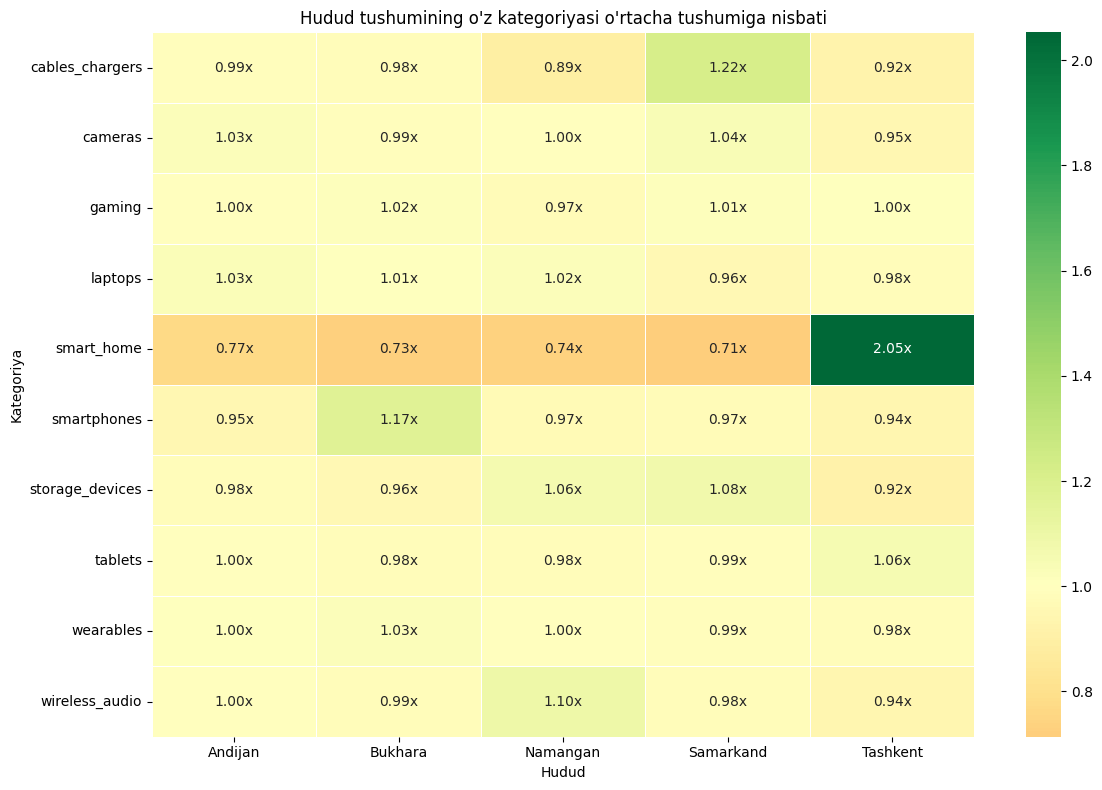

In [28]:
annot = region_category_ratio.map(
    lambda x: f"{x:.2f}x"
)

plt.figure(figsize=(12, 8))

sns.heatmap(
    region_category_ratio,
    annot=annot,
    fmt="",
    cmap="RdYlGn",
    center=1,
    linewidths=0.5
)

plt.title(
    "Hudud tushumining o'z kategoriyasi o'rtacha tushumiga nisbati"
)

plt.xlabel("Hudud")
plt.ylabel("Kategoriya")

plt.tight_layout()
plt.show()

-Heatmapdan ko‘rinadiki, har bir kategoriyaning hududlardagi tushumi shu kategoriyaning o‘rtacha tushumi bilan solishtirilgan. 1x ga teng qiymat o‘rtacha darajani, 1x dan yuqori qiymatlar yuqori, 1x dan past qiymatlar esa past tushumni bildiradi.

### 2023 va 2024-yillardagi tushumlarni o'zgarishi

- Maqsad: qaysi kategoryadagi mahsulot yaxshi ketyabdi va foyda keltiryabdi, Keyinchalik qaysi mahsulotni ko'paytirish kerakligini aniqlash

In [29]:
year_category = (
    df.groupby(['category', 'year'])['monthly_revenue']
      .mean()
      .unstack()
)

year_category

year,2023,2024
category,,
cables_chargers,9919.271833,8231.803833
cameras,18424.027583,17908.306250
gaming,37540.483917,46531.763667
laptops,51112.641417,54911.256167
smart_home,10611.453417,12044.335833
smartphones,168574.361333,162894.674000
storage_devices,7106.891000,6957.056500
tablets,30561.008333,30673.914917
wearables,23480.010167,25078.045167


In [30]:
revenue_change = (
    (year_category[2024] - year_category[2023])
    / year_category[2023]
    * 100
)

revenue_change = revenue_change.sort_values()

revenue_change

category
cables_chargers   -17.012015
smartphones        -3.369247
cameras            -2.799178
storage_devices    -2.108299
tablets             0.369447
wearables           6.805938
laptops             7.431850
smart_home         13.503168
gaming             23.950889
wireless_audio     23.987287
dtype: float64

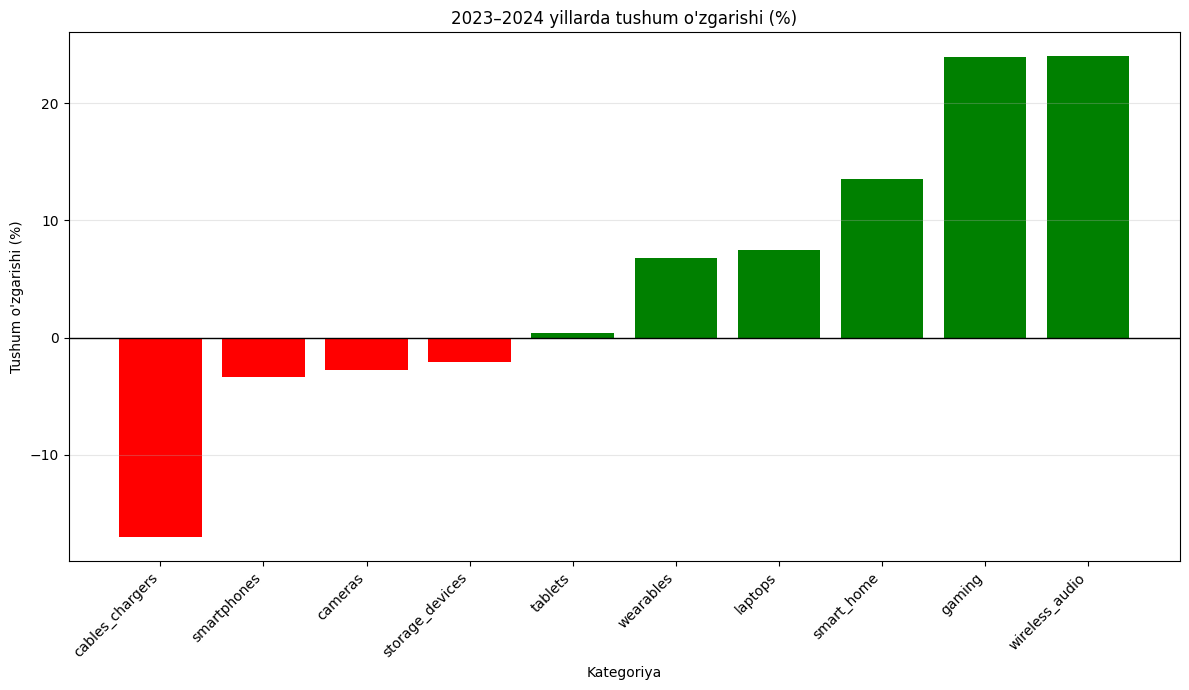

In [31]:
colors = [
    'red' if x < 0 else 'green'
    for x in revenue_change
]

plt.figure(figsize=(12, 7))

plt.bar(
    revenue_change.index,
    revenue_change.values,
    color=colors
)

plt.axhline(0, color='black', linewidth=1)

plt.title("2023–2024 yillarda tushum o'zgarishi (%)")
plt.xlabel("Kategoriya")
plt.ylabel("Tushum o'zgarishi (%)")

plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

-2024-yilda ayrim kategoriyalarda tushum o‘sgan, ayrimlarida esa kamaygan. Grafik orqali qaysi kategoriyalarda tushum o‘sishi yoki pasayishi yuz berganini foizlarda ko‘rish mumkin.

### Chegirmani tasiri

- Maqsad: Chegirma foyda beryabdimi aniqlash

In [32]:
discount_effect = df[
    ['discount_pct', 'units_sold', 'monthly_revenue']
].corr()

discount_effect

,discount_pct,units_sold,monthly_revenue
discount_pct,1.000000,0.230783,0.004737
units_sold,0.230783,1.000000,0.120738
monthly_revenue,0.004737,0.120738,1.000000


In [33]:
df['discount_group'] = pd.cut(
    df['discount_pct'],
    bins=[-1, 5, 10, 15, 20, 25, 100],
    labels=[
        '0–5%',
        '5–10%',
        '10–15%',
        '15–20%',
        '20–25%',
        '25%+'
    ]
)

discount_analysis = (
    df.groupby('discount_group', observed=True)
      .agg(
          avg_units_sold=('units_sold', 'mean'),
          avg_revenue=('monthly_revenue', 'mean')
      )
)

discount_analysis

,avg_units_sold,avg_revenue
discount_group,,
0–5%,199.745892,38379.797588
10–15%,919.000000,19043.305000
15–20%,311.943182,49432.490625
20–25%,342.910256,37731.836603
25%+,333.082873,38229.662099


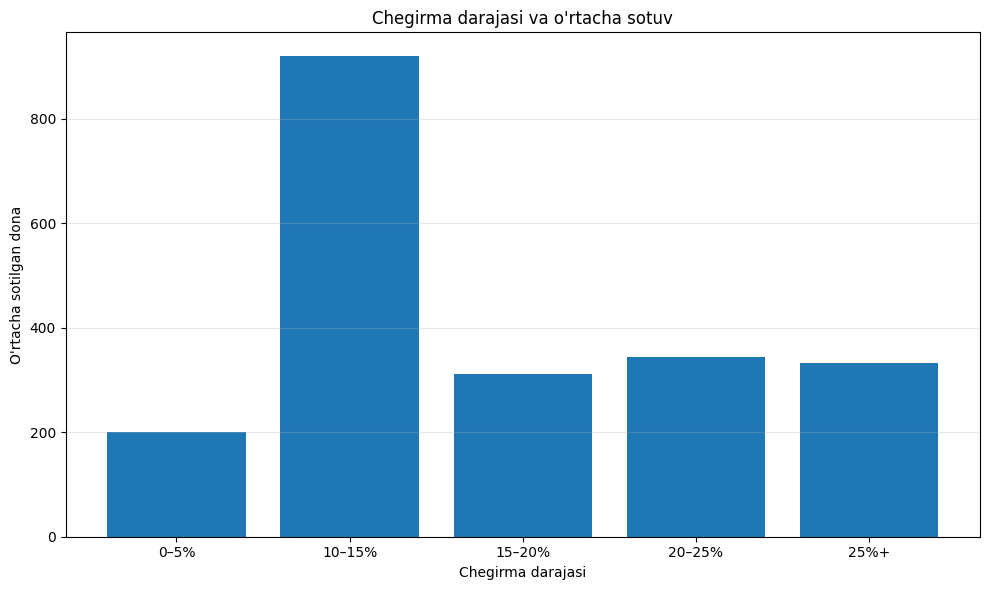

In [34]:
plt.figure(figsize=(10, 6))

plt.bar(
    discount_analysis.index,
    discount_analysis['avg_units_sold']
)

plt.title("Chegirma darajasi va o'rtacha sotuv")
plt.xlabel("Chegirma darajasi")
plt.ylabel("O'rtacha sotilgan dona")

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

-Chegirma darajasi bilan sotuv hajmi o‘rtasida bir xil o‘sish kuzatilmaydi.

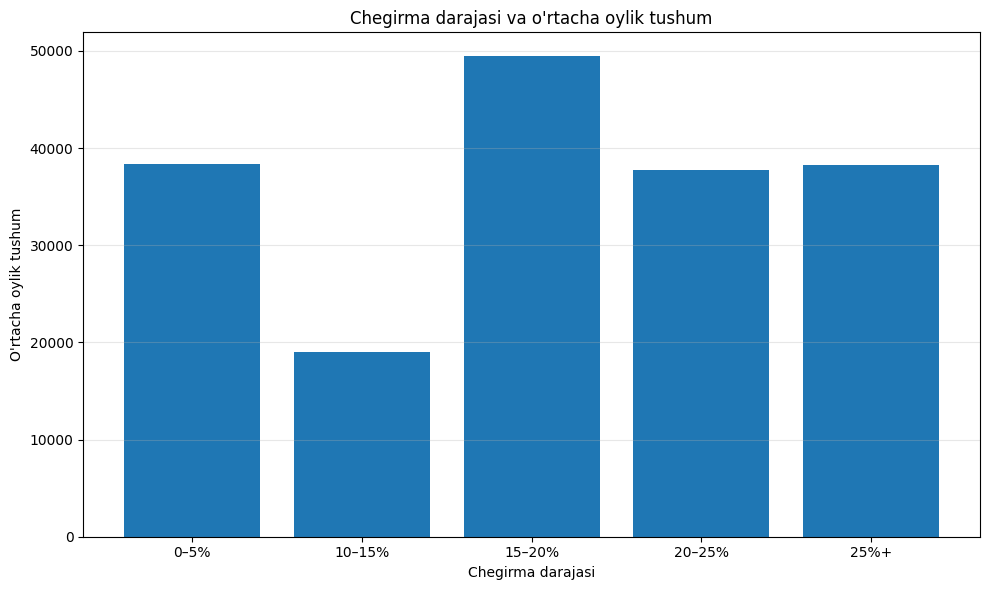

In [35]:
plt.figure(figsize=(10, 6))

plt.bar(
    discount_analysis.index,
    discount_analysis['avg_revenue']
)

plt.title("Chegirma darajasi va o'rtacha oylik tushum")
plt.xlabel("Chegirma darajasi")
plt.ylabel("O'rtacha oylik tushum")

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

-Chegirma darajasi oshishi tushumning muntazam oshishiga olib kelmagan. Bu chegirma har doim ham tushumni oshirmasligini ko‘rsatadi. Yana bir gayrioddiy narsa 10-15 foiz chegirmada sotuv ancha ortgan tushum esa kamaygan

In [36]:
category_discount = (
    df.groupby(
        ['category', 'discount_group'],
        observed=True
    )
    .agg(
        avg_units_sold=('units_sold', 'mean'),
        avg_revenue=('monthly_revenue', 'mean')
    )
    .reset_index()
)

category_discount.head(20)

,category,discount_group,avg_units_sold,avg_revenue
0,cables_chargers,0–5%,501.883041,7837.075439
1,cables_chargers,10–15%,1579.000000,16808.100000
2,cables_chargers,15–20%,1117.933333,12927.002667
3,cables_chargers,20–25%,1210.611111,12657.705000
4,cables_chargers,25%+,1200.971429,11412.495714
5,cameras,0–5%,45.637427,18528.748129
6,cameras,15–20%,60.222222,19447.235000
7,cameras,20–25%,59.000000,17644.753913
8,cameras,25%+,55.357143,15556.591429
9,gaming,0–5%,216.380117,43396.654035


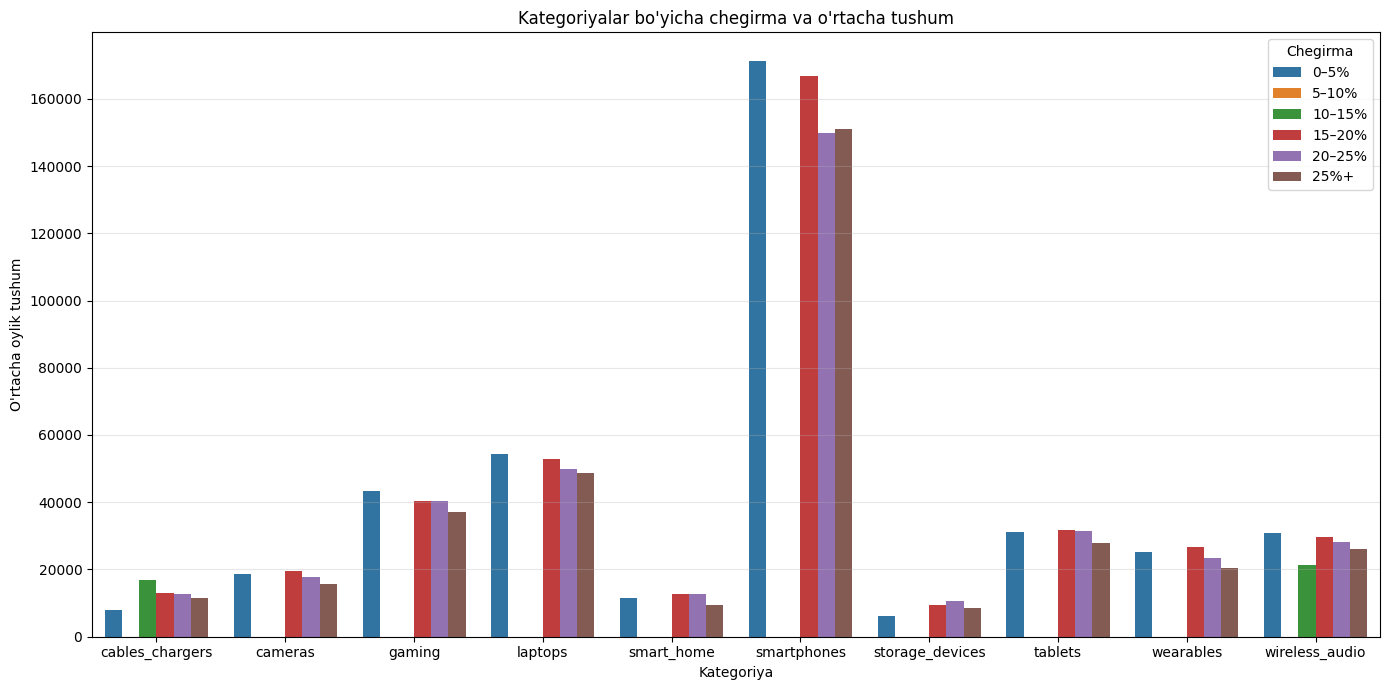

In [37]:
plt.figure(figsize=(14, 7))

sns.barplot(
    data=category_discount,
    x='category',
    y='avg_revenue',
    hue='discount_group'
)

plt.title("Kategoriyalar bo'yicha chegirma va o'rtacha tushum")
plt.xlabel("Kategoriya")
plt.ylabel("O'rtacha oylik tushum")

plt.xticks()
plt.legend(title="Chegirma")
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

- Demak bunda arzon mahsulotlarga 10-15 foiz chegirma bor ekan. Chegirma sotishlar soni ozroq ko'paytirishi mumkin lekin katta tasir ko'rsatmaydi

#Regressiya

- Model oldingi oylardagi ma'lumotlarga qarab o'rganadi: "Shu kategoriya, shu hudud, shu narx va aksiya bor bo'lsa, odatda necha dona sotilgan?" Keyin yangi qator uchun dona sonini taxmin qiladi. Bu tajribali sotuvchining "bu narxda, shu shaharda, aksiya bilan taxminan shuncha ketadi" deyishiga o'xshaydi.

In [38]:
df_new.head()

,category,region,store_type,year,month,avg_unit_price,units_sold,returns,discount_pct,promo_active,customer_rating,competitor_price_index,marketing_spend,monthly_revenue
0,smartphones,Tashkent,offline,2023,1,581.95,298,21,28.5,1,4.6,0.86,5743.41,124478.76
1,smartphones,Tashkent,offline,2023,2,562.49,291,16,19.4,1,4.5,1.13,3337.52,124675.91
2,smartphones,Tashkent,both,2023,3,502.26,361,14,4.8,0,4.4,1.15,10194.22,165918.58
3,smartphones,Tashkent,both,2023,4,577.21,408,21,1.9,0,4.4,1.14,13449.78,219136.04
4,smartphones,Tashkent,both,2023,5,469.80,449,16,1.1,0,4.5,0.89,7736.95,217280.60


- Kiruvchi va target qiymatlarni ajratib oldim

In [39]:
X = df_new.drop(
    columns=[
        'units_sold',
        'monthly_revenue',
        'returns'
    ]
)

y = df_new['units_sold']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (2400, 11)
y shape: (2400,)


- object tipidagi ustunlarni raqamlashtirdim. One-hot encoding

In [40]:
X = pd.get_dummies(
    X,
    columns=[
        'category',
        'region',
        'store_type'
    ],
    drop_first=True,
    dtype = float
)

X.head()

,year,month,avg_unit_price,discount_pct,promo_active,customer_rating,competitor_price_index,marketing_spend,category_cameras,category_gaming,...,category_storage_devices,category_tablets,category_wearables,category_wireless_audio,region_Bukhara,region_Namangan,region_Samarkand,region_Tashkent,store_type_offline,store_type_online
0,2023,1,581.95,28.5,1,4.6,0.86,5743.41,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
1,2023,2,562.49,19.4,1,4.5,1.13,3337.52,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
2,2023,3,502.26,4.8,0,4.4,1.15,10194.22,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,2023,4,577.21,1.9,0,4.4,1.14,13449.78,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,2023,5,469.80,1.1,0,4.5,0.89,7736.95,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


- Train va testga bo'ldim

In [41]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (1920, 23)
Test: (480, 23)


- model qismi

In [42]:
model = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

In [43]:
model.fit(X_train, y_train)

RandomForestRegressor(n_estimators=200, random_state=42)

- x_testni predict qilidim

In [44]:
y_pred = model.predict(X_test)
y_pred[:10]

array([ 155.87 ,  203.385,   84.45 ,   93.065,  192.49 ,  266.165,
         61.275,  101.505,   57.43 , 1168.99 ])

- xatoliklarni ko'rish
- Natija: model o'rtacha 32 dona xato qilyabdi; 94.3 foiz aniqlida ishlayabdi

In [45]:
mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

r2 = r2_score(y_test, y_pred)

print("MAE :", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R²  :", round(r2, 3))

MAE : 32.76
RMSE: 54.93
R²  : 0.943
